<a href="https://colab.research.google.com/github/arkaanrobbani09/Road-Friction-Predictor/blob/main/V2I_RoadFriction_CNN_Transformer_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚗 V2I Road Friction & Aquaplaning Predictor
### Arsitektur: CNN → Transformer → LSTM | Regresi Koefisien Gesek Jalan
---
| Sensor | Keterangan |
|--------|-----------|
| Vehicle Speed | Kecepatan kendaraan (km/h) |
| Wheel Slip Ratio | Persentase slip roda (%) |
| Yaw Rate | Sensor stabilitas limbung (rad/s) |
| Lateral Accel | Akselerasi lateral (m/s²) |
| Brake Pressure | Tekanan rem (bar) |
| Wiper Speed | Kecepatan wiper — proxy curah hujan (RPM) |

**Target Y:** Koefisien Gesek Jalan → Y rendah = bahaya aquaplaning, Y tinggi = traksi aman

## 1. Install & Import

In [ ]:
!pip install tensorflow scikit-learn shap matplotlib numpy -q

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import shap, warnings
warnings.filterwarnings('ignore')
np.random.seed(42); tf.random.set_seed(42)
print("✅ Siap!")

✅ Siap!


## 2. Dataset Sintetis (5000 sampel, 6 sensor, 30 timestep)

X: (5000, 30, 6) | Y: (5000,)
Kering(>0.72): 2286 | Basah(0.42-0.72): 1649 | Licin(<0.42): 1065


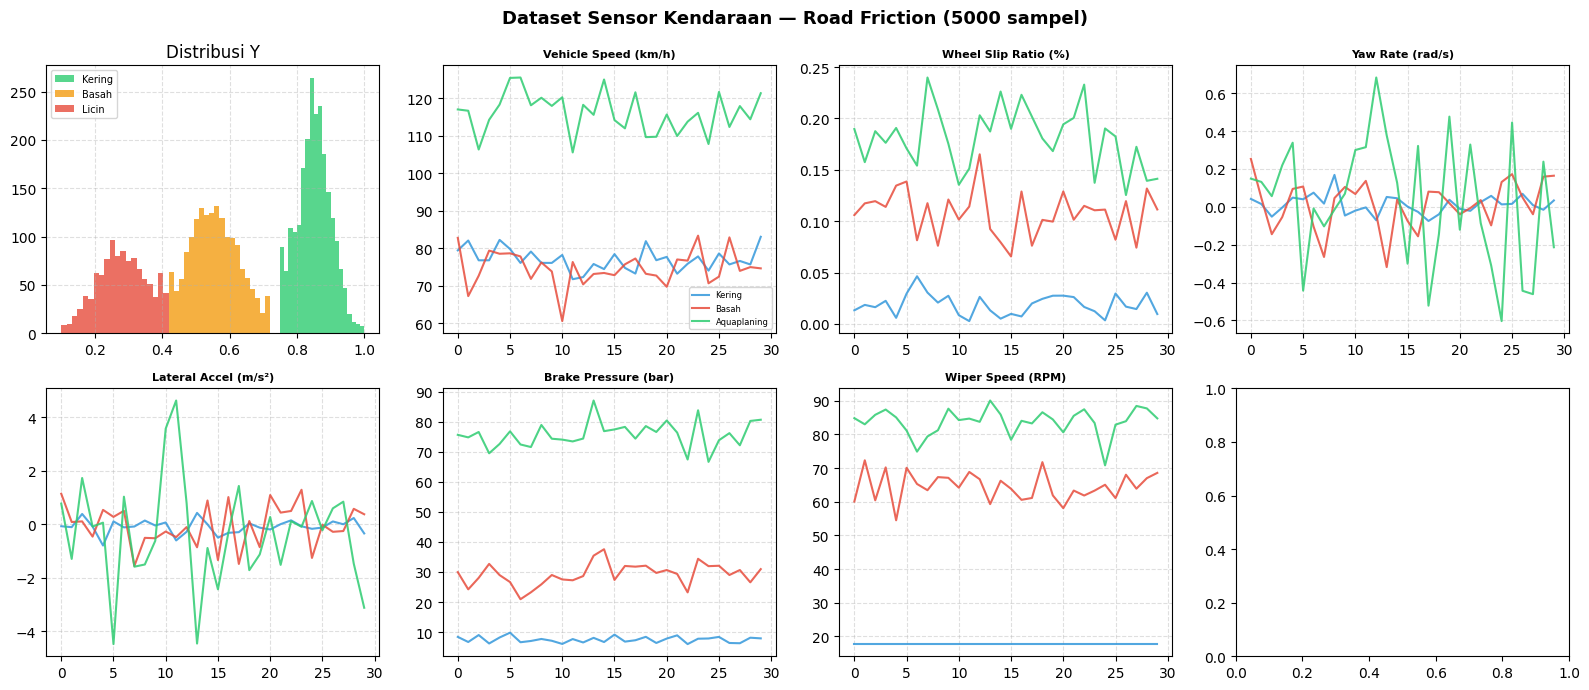

In [ ]:
SENSOR_NAMES = ["Vehicle Speed (km/h)","Wheel Slip Ratio (%)","Yaw Rate (rad/s)",
                "Lateral Accel (m/s²)","Brake Pressure (bar)","Wiper Speed (RPM)"]
SEQ_LEN, N_FEAT, N = 30, 6, 5000

def make_data(n=N, seq_len=SEQ_LEN, seed=42):
    np.random.seed(seed)
    X_all, y_all = [], []
    for _ in range(n):
        cond = np.random.choice([0,1,2], p=[0.45,0.35,0.20])
        if cond == 0:    # Kering
            s  = np.clip(np.random.uniform(30,80) +np.random.randn(seq_len)*3, 10,130)
            sl = np.clip(np.random.uniform(0.01,0.08)+np.random.randn(seq_len)*0.01,0,0.3)
            yr = np.random.randn(seq_len)*0.05
            la = np.random.randn(seq_len)*0.3
            bp = np.clip(np.random.uniform(0,10)+np.random.randn(seq_len),0,50)
            ws = np.zeros(seq_len)+np.random.uniform(0,20)
            y  = np.clip(0.85+np.random.randn()*0.05,0.75,1.0)
        elif cond == 1:  # Basah
            s  = np.clip(np.random.uniform(40,100)+np.random.randn(seq_len)*4,10,130)
            sl = np.clip(np.random.uniform(0.05,0.18)+np.random.randn(seq_len)*0.02,0,0.4)
            yr = np.random.randn(seq_len)*0.15
            la = np.random.randn(seq_len)*0.8
            bp = np.clip(np.random.uniform(5,30)+np.random.randn(seq_len)*3,0,80)
            ws = np.clip(np.random.uniform(40,90)+np.random.randn(seq_len)*5,0,120)
            y  = np.clip(0.55+np.random.randn()*0.08,0.40,0.72)
        else:            # Aquaplaning
            s  = np.clip(np.random.uniform(60,130)+np.random.randn(seq_len)*5,10,140)
            sl = np.clip(np.random.uniform(0.15,0.40)+np.random.randn(seq_len)*0.03,0,0.6)
            yr = np.random.randn(seq_len)*0.35
            la = np.random.randn(seq_len)*1.8
            bp = np.clip(np.random.uniform(20,80)+np.random.randn(seq_len)*5,0,100)
            ws = np.clip(np.random.uniform(80,120)+np.random.randn(seq_len)*5,0,130)
            y  = np.clip(0.28+np.random.randn()*0.07,0.10,0.42)
        X_all.append(np.stack([s,sl,yr,la,bp,ws],axis=1).astype(np.float32))
        y_all.append(np.float32(y))
    return np.array(X_all), np.array(y_all)

X_raw, y = make_data()
sc = StandardScaler()
X  = sc.fit_transform(X_raw.reshape(-1,N_FEAT)).reshape(N,SEQ_LEN,N_FEAT).astype(np.float32)

print(f"X: {X.shape} | Y: {y.shape}")
print(f"Kering(>0.72): {(y>0.72).sum()} | Basah(0.42-0.72): {((y>=0.42)&(y<=0.72)).sum()} | Licin(<0.42): {(y<0.42).sum()}")

# Visualisasi distribusi Y + sinyal sensor
fig, axes = plt.subplots(2, 4, figsize=(16,7))
fig.suptitle("Dataset Sensor Kendaraan — Road Friction (5000 sampel)", fontsize=13, fontweight='bold')
axes[0,0].hist(y[y>0.72],bins=20,color='#2ECC71',alpha=0.8,label='Kering')
axes[0,0].hist(y[(y>=0.42)&(y<=0.72)],bins=20,color='#F39C12',alpha=0.8,label='Basah')
axes[0,0].hist(y[y<0.42],bins=20,color='#E74C3C',alpha=0.8,label='Licin')
axes[0,0].set_title('Distribusi Y'); axes[0,0].legend(fontsize=7); axes[0,0].grid(True,ls='--',alpha=0.4)
colors=['#3498DB','#E74C3C','#2ECC71']
ids=[0,2500,4200]; lbls=['Kering','Basah','Aquaplaning']
for j in range(6):
    ax=axes[(j+1)//4,(j+1)%4]
    for si,(sid,lbl) in enumerate(zip(ids,lbls)):
        ax.plot(X_raw[sid,:,j],color=colors[si],lw=1.5,label=lbl,alpha=0.85)
    ax.set_title(SENSOR_NAMES[j],fontsize=8,fontweight='bold')
    ax.grid(True,ls='--',alpha=0.4)
    if j==0: ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

## 3. Arsitektur CNN → Transformer → LSTM

In [ ]:
def build_model(seq_len, n_feat, cnn_f=64, heads=4, ff_dim=128, lstm_u=64, drop=0.2, lr=0.001):
    """
    CNN Block        : Conv1D (causal) — ekstrak pola lokal antar sensor
    Transformer Block: Multi-Head Attention — konteks global antar timestep
    LSTM Block       : Memori temporal jangka panjang
    Output           : Dense(1) tanpa aktivasi — regresi nilai Y kontinu
    """
    inp = layers.Input(shape=(seq_len, n_feat))
    # CNN
    x = layers.Conv1D(cnn_f, 3, padding='causal', activation='relu')(inp)
    x = layers.Conv1D(cnn_f, 3, padding='causal', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(drop)(x)
    # Transformer
    a = layers.MultiHeadAttention(num_heads=heads, key_dim=cnn_f//heads)(x, x)
    x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(drop)(a))
    f = layers.Dense(ff_dim, activation='relu')(x)
    f = layers.Dense(cnn_f)(f)
    x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(drop)(f))
    # LSTM
    x = layers.LSTM(lstm_u)(x)
    x = layers.Dropout(drop)(x)
    x = layers.Dense(32, activation='relu')(x)
    out = layers.Dense(1)(x)
    m = models.Model(inp, out)
    m.compile(tf.keras.optimizers.Adam(lr), loss='mse', metrics=['mae'])
    return m

build_model(SEQ_LEN, N_FEAT).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 6)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 64)    │      1,216 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 30, 64)    │     12,352 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 30, 64)    │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 30, 64)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 64)    │     16,640 │ dropout[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 30, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 64)    │          0 │ dropout[0][0],    │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 30, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 30, 64)    │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 30, 64)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 82,433 (322.00 KB)

 Trainable params: 82,305 (321.50 KB)

 Non-trainable params: 128 (512.00 B)

## 4. Analisa Bias-Variance dari Kurva Training
> Setiap konfigurasi dilatih penuh dan kurva loss-nya divisualisasikan beserta diagnosis otomatis:
> - 🔴 **High Bias (Underfitting)**: Training loss tinggi & stagnan — model terlalu sederhana
> - 🟠 **High Variance (Overfitting)**: Val loss membentuk huruf 'U' atau gap lebar terhadap train loss
> - 🟢 **Good Trade-off**: Kedua kurva turun bersama & konvergen tanpa gap berlebih

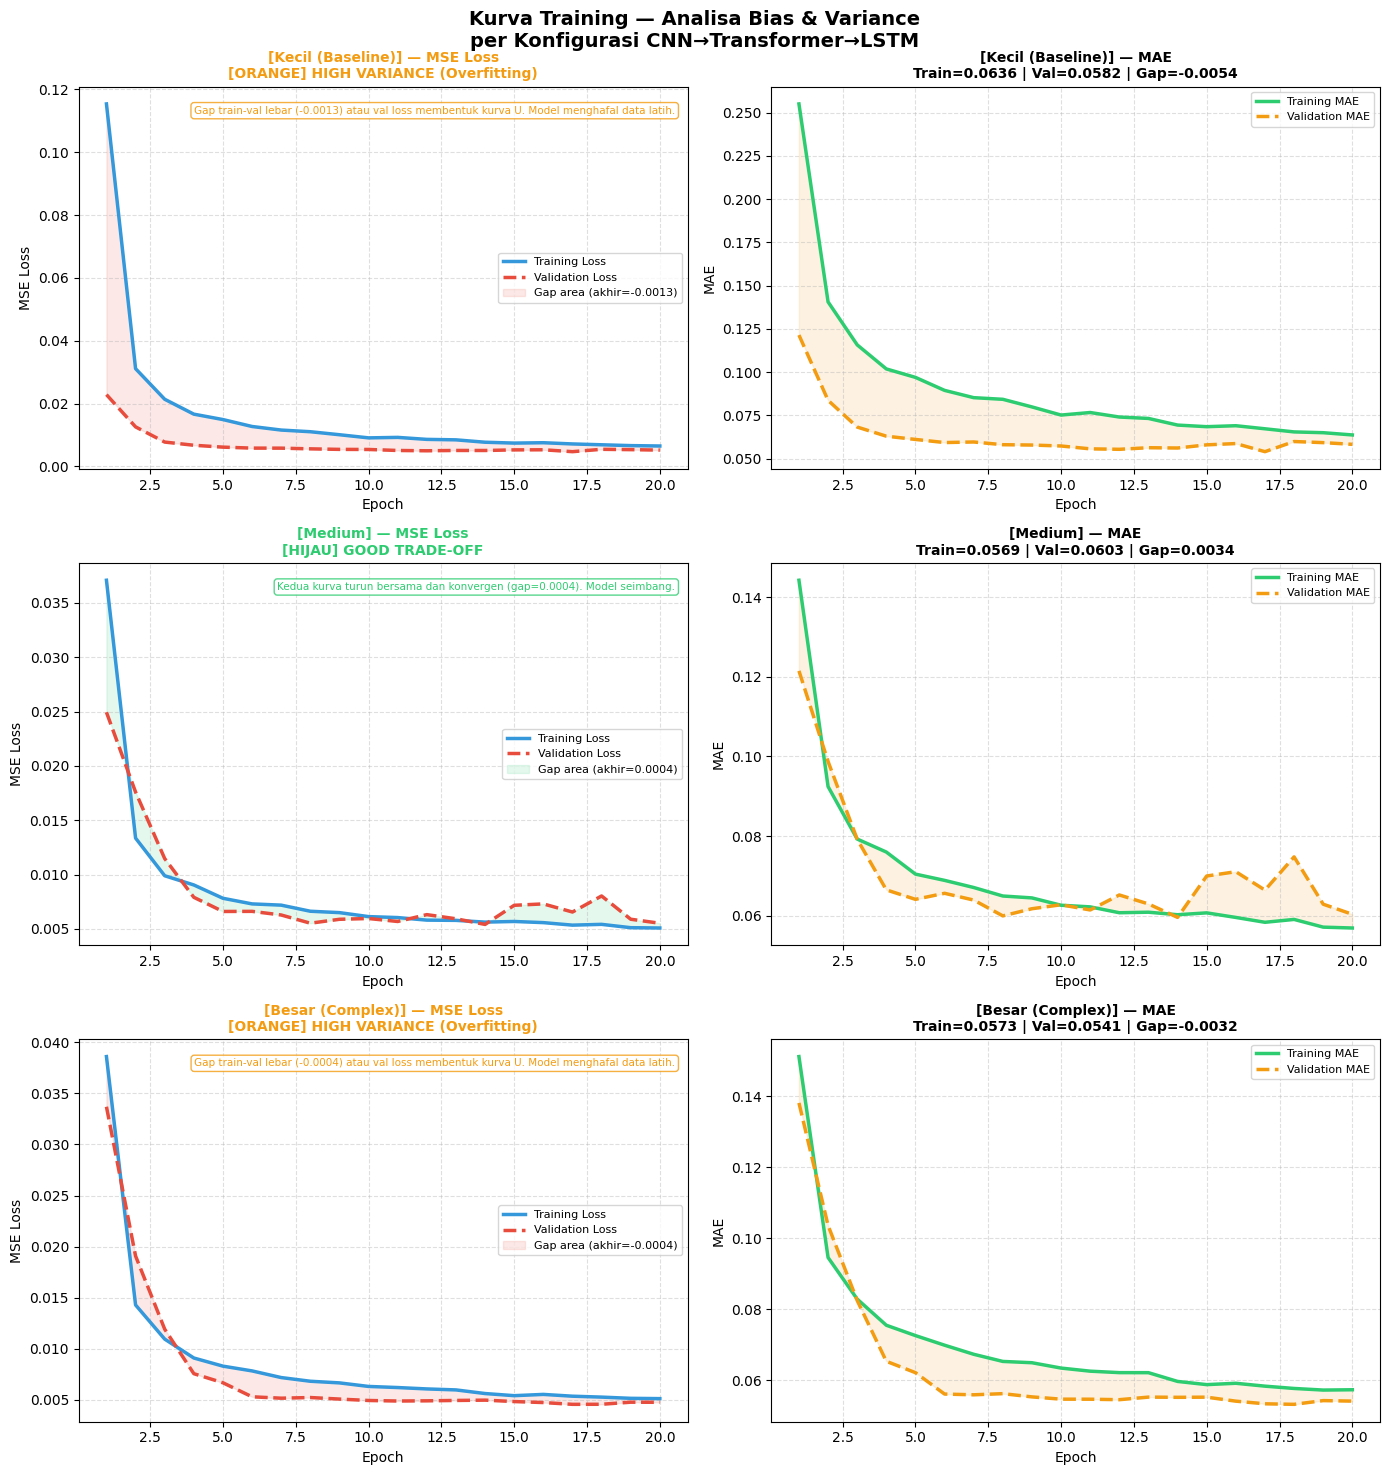


  RINGKASAN ANALISA BIAS-VARIANCE — DARI KURVA TRAINING
  Konfigurasi             Train MSE    Val MSE        Gap  Diagnosis
  ---------------------------------------------------------------
  Kecil (Baseline)          0.00648    0.00517   -0.00131  HIGH VARIANCE (Overfitting)
  Medium                    0.00509    0.00553    0.00044  GOOD TRADE-OFF
  Besar (Complex)           0.00511    0.00475   -0.00036  HIGH VARIANCE (Overfitting)

  Panduan membaca kurva:
  [MERAH]  High Bias     : Train loss tinggi & stagnan (underfitting)
  [ORANGE] High Variance : Val loss naik / gap lebar (overfitting)
  [HIJAU]  Good Trade-off: Kedua kurva konvergen tanpa gap berlebih


In [ ]:
param_grid = [
    {'cnn_f':32,  'heads':2, 'ff_dim':64,  'lstm_u':32,  'lr':0.001,  'label':'Kecil (Baseline)'},
    {'cnn_f':64,  'heads':4, 'ff_dim':128, 'lstm_u':64,  'lr':0.001,  'label':'Medium'},
    {'cnn_f':128, 'heads':4, 'ff_dim':256, 'lstm_u':128, 'lr':0.0005, 'label':'Besar (Complex)'},
]
kf        = KFold(n_splits=3, shuffle=True, random_state=42)
EPOCHS_BV = 20

X_tr_bv, X_vl_bv, y_tr_bv, y_vl_bv = train_test_split(X, y, test_size=0.25, random_state=42)

all_histories, diagnoses = [], []
fig, axes = plt.subplots(len(param_grid), 2, figsize=(14, 5*len(param_grid)))
fig.suptitle("Kurva Training — Analisa Bias & Variance\nper Konfigurasi CNN→Transformer→LSTM",
             fontsize=14, fontweight='bold')

for i, p in enumerate(param_grid):
    m = build_model(SEQ_LEN, N_FEAT, p['cnn_f'], p['heads'], p['ff_dim'], p['lstm_u'], lr=p['lr'])
    h = m.fit(X_tr_bv, y_tr_bv, epochs=EPOCHS_BV, batch_size=128, verbose=0,
              validation_data=(X_vl_bv, y_vl_bv))
    all_histories.append(h)

    tr_loss = h.history['loss']
    vl_loss = h.history['val_loss']
    tr_mae  = h.history['mae']
    vl_mae  = h.history['val_mae']
    ep      = range(1, len(tr_loss)+1)

    final_tr  = tr_loss[-1]
    final_vl  = vl_loss[-1]
    gap       = final_vl - final_tr
    cutoff    = int(len(vl_loss) * 0.7)
    vl_rising = vl_loss[-1] > min(vl_loss[cutoff:])

    # Diagnosis otomatis
    if final_tr > 0.04:
        diag   = "HIGH BIAS (Underfitting)"
        detail = "Training loss stagnan tinggi. Model terlalu sederhana, tidak mampu mempelajari pola data latih."
        color  = '#E74C3C'
        icon   = "MERAH"
    elif gap > 0.015 or vl_rising:
        diag   = "HIGH VARIANCE (Overfitting)"
        detail = f"Gap train-val lebar ({gap:.4f}) atau val loss membentuk kurva U. Model menghafal data latih."
        color  = '#F39C12'
        icon   = "ORANGE"
    else:
        diag   = "GOOD TRADE-OFF"
        detail = f"Kedua kurva turun bersama dan konvergen (gap={gap:.4f}). Model seimbang."
        color  = '#2ECC71'
        icon   = "HIJAU"

    diagnoses.append({'label': p['label'], 'diag': diag, 'gap': gap, 'tr': final_tr, 'vl': final_vl})

    # Plot Loss
    ax_loss = axes[i, 0]
    ax_loss.plot(ep, tr_loss, color='#3498DB', lw=2.5, label='Training Loss')
    ax_loss.plot(ep, vl_loss, color='#E74C3C', lw=2.5, ls='--', label='Validation Loss')
    ax_loss.fill_between(ep, tr_loss, vl_loss, alpha=0.12,
                         color='#E74C3C' if (gap > 0.015 or vl_rising) else '#2ECC71',
                         label=f'Gap area (akhir={gap:.4f})')
    ax_loss.set_title(f"[{p['label']}] — MSE Loss\n[{icon}] {diag}",
                      fontsize=10, fontweight='bold', color=color)
    ax_loss.set_xlabel('Epoch'); ax_loss.set_ylabel('MSE Loss')
    ax_loss.legend(fontsize=8); ax_loss.grid(True, ls='--', alpha=0.4)
    ax_loss.text(0.98, 0.95, detail, transform=ax_loss.transAxes,
                 fontsize=7.5, va='top', ha='right', color=color,
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=color, alpha=0.8),
                 wrap=True)

    # Plot MAE
    ax_mae = axes[i, 1]
    ax_mae.plot(ep, tr_mae, color='#2ECC71', lw=2.5, label='Training MAE')
    ax_mae.plot(ep, vl_mae, color='#F39C12', lw=2.5, ls='--', label='Validation MAE')
    gap_mae = vl_mae[-1] - tr_mae[-1]
    ax_mae.fill_between(ep, tr_mae, vl_mae, alpha=0.12, color='#F39C12')
    ax_mae.set_title(f"[{p['label']}] — MAE\nTrain={tr_mae[-1]:.4f} | Val={vl_mae[-1]:.4f} | Gap={gap_mae:.4f}",
                     fontsize=10, fontweight='bold')
    ax_mae.set_xlabel('Epoch'); ax_mae.set_ylabel('MAE')
    ax_mae.legend(fontsize=8); ax_mae.grid(True, ls='--', alpha=0.4)

plt.tight_layout(); plt.show()

print("\n" + "="*65)
print("  RINGKASAN ANALISA BIAS-VARIANCE — DARI KURVA TRAINING")
print("="*65)
print(f"  {'Konfigurasi':<22} {'Train MSE':>10} {'Val MSE':>10} {'Gap':>10}  Diagnosis")
print("  " + "-"*63)
for d in diagnoses:
    print(f"  {d['label']:<22} {d['tr']:>10.5f} {d['vl']:>10.5f} {d['gap']:>10.5f}  {d['diag']}")
print("="*65)
print("\n  Panduan membaca kurva:")
print("  [MERAH]  High Bias     : Train loss tinggi & stagnan (underfitting)")
print("  [ORANGE] High Variance : Val loss naik / gap lebar (overfitting)")
print("  [HIJAU]  Good Trade-off: Kedua kurva konvergen tanpa gap berlebih")


## 5. Hyperparameter Tuning dengan K-Fold

In [ ]:
results, best_params, best_loss = [], None, float('inf')

for p in param_grid:
    tr_l, vl_l, tr_m, vl_m = [], [], [], []
    for ti, vi in kf.split(X):
        m = build_model(SEQ_LEN, N_FEAT, p['cnn_f'], p['heads'], p['ff_dim'], p['lstm_u'], lr=p['lr'])
        h = m.fit(X[ti], y[ti], epochs=12, batch_size=128, verbose=0,
                  validation_data=(X[vi], y[vi]))
        tr_l.append(h.history['loss'][-1]);   vl_l.append(h.history['val_loss'][-1])
        tr_m.append(h.history['mae'][-1]);    vl_m.append(h.history['val_mae'][-1])
    atr, avl = np.mean(tr_l), np.mean(vl_l)
    gap = avl - atr
    results.append({'label':p['label'],'params':p,'tr':atr,'vl':avl,
                    'trm':np.mean(tr_m),'vlm':np.mean(vl_m),'gap':gap})
    diag = 'HIGH BIAS' if atr>0.05 else 'HIGH VARIANCE' if gap>0.01 else 'GOOD ✓'
    print(f"[{p['label']:20s}] Train:{atr:.5f} | Val:{avl:.5f} | Gap:{gap:.5f} → {diag}")
    if avl < best_loss: best_loss, best_params = avl, p

print(f"\n🎯 Terbaik: [{best_params['label']}] | Val Loss: {best_loss:.5f}")

# Plot Bias-Variance K-Fold
lbs=[r['label'] for r in results]; x=np.arange(len(lbs)); w=0.35
fig,axes=plt.subplots(1,3,figsize=(16,4))
fig.suptitle('Bias-Variance (K-Fold) — CNN→Transformer→LSTM', fontweight='bold')
for ax,(a,b,ttl,c1,c2) in zip(axes,[
    ([r['tr'] for r in results],[r['vl'] for r in results],'MSE Loss','#3498DB','#E74C3C'),
    ([r['trm'] for r in results],[r['vlm'] for r in results],'MAE','#2ECC71','#F39C12')]):
    b1=ax.bar(x-w/2,a,w,label='Train',color=c1,alpha=0.85)
    b2=ax.bar(x+w/2,b,w,label='Val',color=c2,alpha=0.85)
    ax.set_title(ttl); ax.set_xticks(x); ax.set_xticklabels(lbs,fontsize=8)
    ax.legend(); ax.grid(True,ls='--',alpha=0.4,axis='y')
    for bar in list(b1)+list(b2): ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.0001,
                                           f'{bar.get_height():.4f}',ha='center',fontsize=7)
gaps=[r['gap'] for r in results]
gc=['#2ECC71' if g<0.002 else '#F39C12' if g<0.01 else '#E74C3C' for g in gaps]
axes[2].bar(lbs,gaps,color=gc,edgecolor='black',alpha=0.85)
axes[2].axhline(0.002,color='green',ls='--',lw=1.5,label='Stabil')
axes[2].axhline(0.01,color='orange',ls='--',lw=1.5,label='Overfit')
axes[2].set_title('Gap = Val − Train MSE'); axes[2].legend(fontsize=8)
axes[2].set_xticklabels(lbs,fontsize=8); axes[2].grid(True,ls='--',alpha=0.4,axis='y')
plt.tight_layout(); plt.show()

## 6. Evaluasi Final + Prediksi vs Aktual

Test MSE: 0.00460 | Test MAE: 0.05393


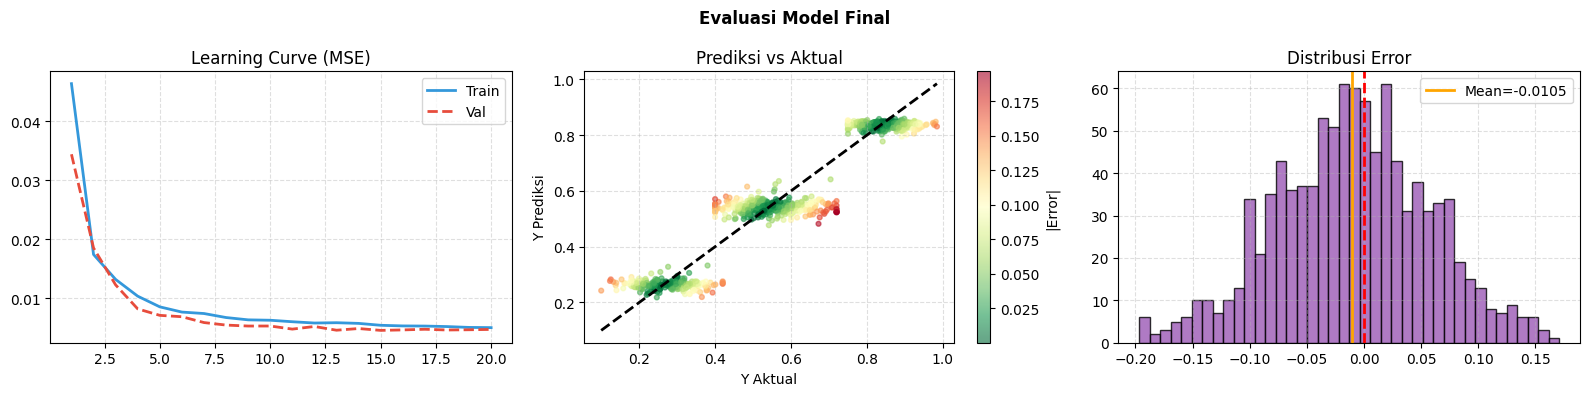

In [ ]:
X_tr,X_te,y_tr,y_te = train_test_split(X, y, test_size=0.2, random_state=42)
model = build_model(SEQ_LEN, N_FEAT, best_params['cnn_f'], best_params['heads'],
                    best_params['ff_dim'], best_params['lstm_u'], lr=best_params['lr'])
hist = model.fit(X_tr, y_tr, epochs=30, batch_size=128, validation_data=(X_te,y_te),
                 callbacks=[callbacks.EarlyStopping(patience=5, restore_best_weights=True),
                             callbacks.ReduceLROnPlateau(patience=3, factor=0.5)], verbose=0)
loss_te, mae_te = model.evaluate(X_te, y_te, verbose=0)
y_pred = model.predict(X_te, verbose=0).flatten()
err    = y_pred - y_te
print(f"Test MSE: {loss_te:.5f} | Test MAE: {mae_te:.5f}")

ep = range(1, len(hist.history['loss'])+1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Evaluasi Model Final', fontweight='bold')

axes[0].plot(ep, hist.history['loss'],     color='#3498DB', lw=2, label='Train')
axes[0].plot(ep, hist.history['val_loss'], color='#E74C3C', lw=2, ls='--', label='Val')
axes[0].set_title('Learning Curve (MSE)'); axes[0].legend(); axes[0].grid(True,ls='--',alpha=0.4)

sc = axes[1].scatter(y_te, y_pred, c=np.abs(err), cmap='RdYlGn_r', s=12, alpha=0.6)
axes[1].plot([y_te.min(),y_te.max()],[y_te.min(),y_te.max()],'k--',lw=2)
plt.colorbar(sc, ax=axes[1], label='|Error|')
axes[1].set_xlabel('Y Aktual'); axes[1].set_ylabel('Y Prediksi')
axes[1].set_title('Prediksi vs Aktual'); axes[1].grid(True,ls='--',alpha=0.4)

axes[2].hist(err, bins=40, color='#9B59B6', edgecolor='black', alpha=0.8)
axes[2].axvline(0, color='red', lw=2, ls='--')
axes[2].axvline(err.mean(), color='orange', lw=2, label=f'Mean={err.mean():.4f}')
axes[2].set_title('Distribusi Error'); axes[2].legend(); axes[2].grid(True,ls='--',alpha=0.4)
plt.tight_layout(); plt.show()

## 7. Kestabilan K-Fold (Parameter Terbaik)

In [ ]:
fold_mse, fold_mae = [], []
for i,(ti,vi) in enumerate(kf.split(X)):
    m = build_model(SEQ_LEN, N_FEAT, best_params['cnn_f'], best_params['heads'],
                    best_params['ff_dim'], best_params['lstm_u'], lr=best_params['lr'])
    m.fit(X[ti], y[ti], epochs=15, batch_size=128, verbose=0)
    l, mae = m.evaluate(X[vi], y[vi], verbose=0)
    fold_mse.append(l); fold_mae.append(mae)
    print(f"  Fold {i+1}: MSE={l:.5f} | MAE={mae:.5f}")
print(f"\n  Mean MSE: {np.mean(fold_mse):.5f} ± {np.std(fold_mse):.5f}")
print(f"  Mean MAE: {np.mean(fold_mae):.5f} ± {np.std(fold_mae):.5f}")
diag = "✅ STABIL" if np.std(fold_mse)<0.001 else "⚠️ CUKUP STABIL" if np.std(fold_mse)<0.005 else "❌ TIDAK STABIL"
print(f"  {diag}")

## 8. Analisis SHAP — Sensor Paling Berpengaruh

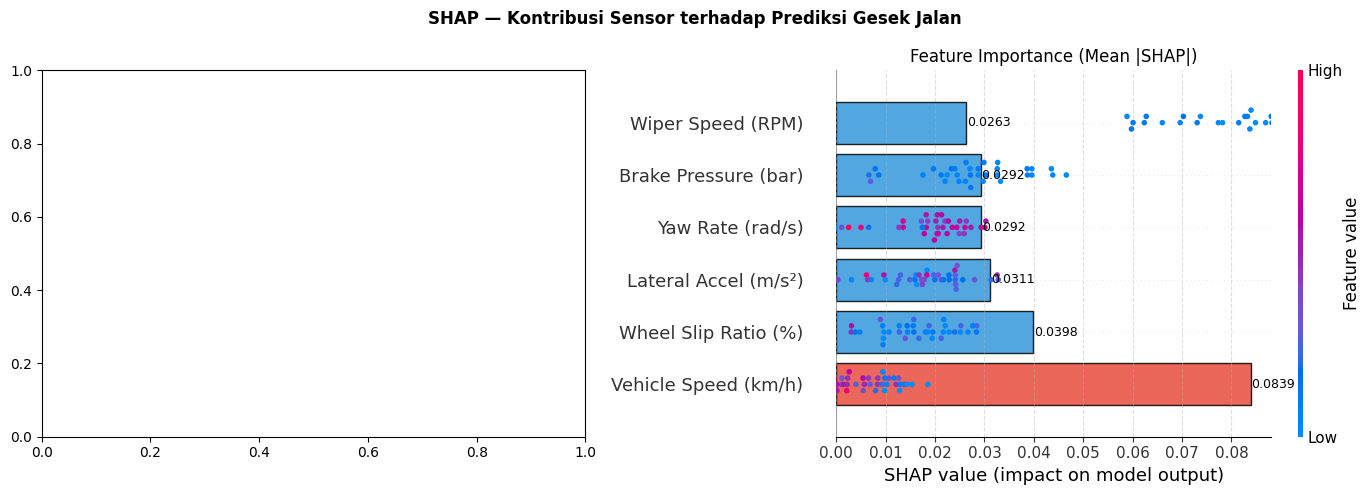


=== RANKING SENSOR ===
  #1 Wiper Speed (RPM)           : 0.0839  ← PALING PENTING
  #2 Brake Pressure (bar)        : 0.0398
  #3 Yaw Rate (rad/s)            : 0.0311
  #4 Wheel Slip Ratio (%)        : 0.0292
  #5 Lateral Accel (m/s²)        : 0.0292
  #6 Vehicle Speed (km/h)        : 0.0263


In [ ]:
explainer   = shap.GradientExplainer(model, X[:200])
shap_vals   = explainer.shap_values(X[200:250])
shap_2d     = np.sum(shap_vals.squeeze(-1), axis=1)
shap_abs_2d = np.sum(np.abs(shap_vals.squeeze(-1)), axis=1)
X_2d        = X[200:250].mean(axis=1)
mean_imp    = shap_abs_2d.mean(axis=0)
sidx        = np.argsort(mean_imp)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14,5))
fig.suptitle('SHAP — Kontribusi Sensor terhadap Prediksi Gesek Jalan', fontweight='bold')
shap.summary_plot(shap_2d, X_2d, feature_names=SENSOR_NAMES, show=False, plot_size=None)
axes[1].barh([SENSOR_NAMES[i] for i in sidx], mean_imp[sidx],
              color=['#E74C3C']+['#3498DB']*(N_FEAT-1), edgecolor='black', alpha=0.85)
for bar,val in zip(axes[1].patches, mean_imp[sidx]):
    axes[1].text(val+0.0002, bar.get_y()+bar.get_height()/2, f'{val:.4f}', va='center', fontsize=9)
axes[1].set_title('Feature Importance (Mean |SHAP|)'); axes[1].grid(True,ls='--',alpha=0.4,axis='x')
plt.tight_layout(); plt.show()

print("\n=== RANKING SENSOR ===")
for r,i in enumerate(sidx):
    print(f"  #{r+1} {SENSOR_NAMES[i]:<28}: {mean_imp[i]:.4f}{'  ← PALING PENTING' if r==0 else ''}")

## 9. Ringkasan Hasil

In [ ]:
print("="*58)
print("  HASIL — V2I ROAD FRICTION PREDICTOR")
print("  CNN → Transformer → LSTM")
print("="*58)
print(f"  Dataset      : {N} sampel | {SEQ_LEN} timestep | {N_FEAT} sensor")
print(f"  Best Config  : [{best_params['label']}]")
print(f"  Test MSE     : {loss_te:.5f}")
print(f"  Test MAE     : {mae_te:.5f}  (±{mae_te:.3f} koef. gesek)")
print(f"  K-Fold MSE   : {np.mean(fold_mse):.5f} ± {np.std(fold_mse):.5f}")
print(f"  Sensor #1    : {SENSOR_NAMES[sidx[0]]}")
print("="*58)
print("\n  Analisa Bias-Variance (dari kurva training):")
for d in diagnoses:
    print(f"    [{d['label']:20s}] gap={d['gap']:.5f}  {d['diag']}")
print("="*58)
print("  Y > 0.72  → ✅ Aman")
print("  0.42–0.72 → 🟡 Jalan Basah")
print("  Y < 0.42  → ⚠️  Bahaya Aquaplaning")

  HASIL — V2I ROAD FRICTION PREDICTOR
  CNN → Transformer → LSTM
  Dataset      : 5000 sampel | 30 timestep | 6 sensor
  Best Config  : [Besar (Complex)]
  Test MSE     : 0.00460
  Test MAE     : 0.05393  (±0.054 koef. gesek)
  K-Fold MSE   : 0.00496 ± 0.00023
  Sensor #1    : Wiper Speed (RPM)

  Analisa Bias-Variance (dari kurva training):
    [Kecil (Baseline)    ] gap=0.00267  HIGH VARIANCE (Overfitting)
    [Medium              ] gap=0.00041  GOOD TRADE-OFF
    [Besar (Complex)     ] gap=-0.00063  GOOD TRADE-OFF
  Y > 0.72  → ✅ Aman
  0.42–0.72 → 🟡 Jalan Basah
  Y < 0.42  → ⚠️  Bahaya Aquaplaning
